# Hello OBCH5

This notebook introduce an analysis-ready HDF5-based data management of 4D objects-by-change (4D-OBCs) from 4D point clouds extracted by [py4dgeo](https://github.com/3dgeo-heidelberg/py4dgeo).

The HDF5 file contains two main groups:

- /analysis: point-wise spatiotemporal surface-change data
- /obcs: detected 4D-OBC metadata and point memberships

OBCH5 provides a convenient interface to both groups using xarray, pandas, and NumPy.


## 1. Imports

In [1]:
from pathlib import Path
import os

PROJECT_ROOT = Path.cwd().parent
os.chdir(PROJECT_ROOT)

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr # install with: conda install -c conda-forge xarray h5netcdf h5py dask netCDF4 bottleneck

from src.obc_h5 import OBCH5

## 2. Load data

The data is accessed via [xarray](https://docs.xarray.dev/en/stable/index.html)

In [2]:
# Define your path to hdf5 file
obch5_path = Path(f"{PROJECT_ROOT}/0_data/FinRiverbank.h5")

In [3]:
# Open it with OBCH5
data = OBCH5(obch5_path)

In [4]:
print("Dataset:", data.dataset_id)
print("Preferred distance variable:", data.distance_variable)
print("xyz shape:", data.xyz.shape)

Dataset: FinRiverbank
Preferred distance variable: smoothed_distance
xyz shape: (195605, 3)


## 3. Inspect data

he HDF5 file contains two main groups:
```
dataset.h5
├── /analysis
└── /obcs
```

`/analysis`: The analysis group contains the core-point coordinates and point-wise time series. Its main dimensions are:
- point: py4dgeo core-point index
- time: observation time index

Most spatiotemporal observation therefore have the form: `(point, time)`

In [5]:
data.analysis

<xarray.Dataset> Size: 10GB
Dimensions:                   (point: 195605, time: 909)
Coordinates:
  * point                     (point) int64 2MB 0 1 2 3 ... 195602 195603 195604
  * time                      (time) datetime64[ns] 7kB 2021-04-18T14:45:00 ....
Data variables:
    x                         (point) float64 2MB 5.396e+05 ... 5.396e+05
    y                         (point) float64 2MB 7.757e+06 ... 7.757e+06
    z                         (point) float64 2MB 20.87 20.79 ... 14.61 14.61
    m3c2_distance             (point, time) float64 1GB ...
    smoothed_distance         (point, time) float64 1GB ...
    uncertainty_lodetection   (point, time) float64 1GB ...
    uncertainty_spread1       (point, time) float64 1GB ...
    uncertainty_num_samples1  (point, time) int64 1GB ...
    uncertainty_spread2       (point, time) float64 1GB ...
    uncertainty_num_samples2  (point, time) int64 1GB ...
Attributes:
    coordinates_complete:           true
    schema_name:                    4D-OBC HDF5 analysis
    schema_version:                 0.1.0
    dataset_id:                     FinRiverbank
    point_index_semantics:          Original py4dgeo core-point index
    time_index_semantics:           Original py4dgeo time index
    obc_end_epoch_semantics:        Inclusive
    smoothed_distance_available:    true
    distance_for_compute_variable:  smoothed_distance
    uncertainties_complete:         true
    conversion_complete:            true

`/obcs`: The OBC group contains one metadata record per detected object and a sparse representation of which core points belong to each object.

In [6]:
data.obcs

<xarray.Dataset> Size: 574MB
Dimensions:               (object: 2338, object_offset: 2339,
                           membership: 47782561)
Dimensions without coordinates: object, object_offset, membership
Data variables: (12/21)
    object_id             (object) <U26 243kB ...
    display_id            (object) <U23 215kB ...
    n_points              (object) int32 9kB ...
    object_point_offsets  (object_offset) int64 19kB ...
    start_epoch           (object) int32 9kB ...
    end_epoch             (object) int32 9kB ...
    ...                    ...
    zmin                  (object) float64 19kB ...
    xmax                  (object) float64 19kB ...
    ymax                  (object) float64 19kB ...
    zmax                  (object) float64 19kB ...
    object_point_indices  (membership) int32 191MB ...
    object_distance       (membership) float64 382MB ...
Attributes:
    schema_name:                4D-OBC HDF5 OBC table
    schema_version:             0.1.0
    dataset_id:                 FinRiverbank
    membership_representation:  CSR-like object-to-point index
    obc_end_epoch_semantics:    Inclusive
    object_id_scheme:           ULID
    display_id_semantics:       dataset-local, not a global identifier
    object_distance_stored:     true
    reverse_index_stored:       false
    obcs_written:               2338
    conversion_complete:        true

For object `i`, its member points are stored as:
```
a = object_point_offsets[i]
b = object_point_offsets[i + 1]

points = object_point_indices[a:b]
```

Inspect the OBC tables:

In [7]:
objects = data.object_table()

objects.head()

,object,object_id,display_id,start_epoch,end_epoch,seed_point_index,seed_start_epoch,seed_end_epoch,threshold,n_points,...,ymin,zmin,xmax,ymax,zmax,start_time,end_time,seed_x,seed_y,seed_z
0,0,01M3M6J6DDERDPRQCZJ505D5KZ,FinRiverbank-obc-000000,517,520,240,517,520,0.8,54,...,7757307.847,29.902,539623.972,7757308.488,30.571,2021-07-21 14:45:00,2021-07-21 20:45:00,539623.769,7757308.202,30.211
1,1,01M3M6J6DDE753Y6N8ZSPCSWA1,FinRiverbank-obc-000001,549,553,204,549,553,0.9,401,...,7757306.604,29.424,539623.972,7757308.541,31.475,2021-07-26 08:45:00,2021-07-26 16:45:00,539623.861,7757308.493,29.622
2,2,01M3M6J6DDF7KC7EY9Q67J0RYN,FinRiverbank-obc-000002,590,593,204,590,593,0.9,405,...,7757306.604,29.399,539623.972,7757308.541,31.475,2021-08-01 10:45:00,2021-08-01 16:45:00,539623.861,7757308.493,29.622
3,3,01M3M6J6DDTP68SJ5MG1AVF0KD,FinRiverbank-obc-000003,594,597,204,594,597,0.5,390,...,7757306.604,29.399,539623.972,7757308.541,31.458,2021-08-01 18:45:00,2021-08-02 14:45:00,539623.861,7757308.493,29.622
4,4,01M3M6J6DDDJCYP6QF0D5K7CY5,FinRiverbank-obc-000004,713,716,204,713,716,0.7,404,...,7757306.604,29.509,539623.972,7757308.541,31.475,2021-08-22 08:45:00,2021-08-22 14:45:00,539623.861,7757308.493,29.622


## 4. Queries

The complete corepoint coordinate array is:

In [8]:
xyz = data.xyz
xyz.shape

(195605, 3)

A simple spatial overview:

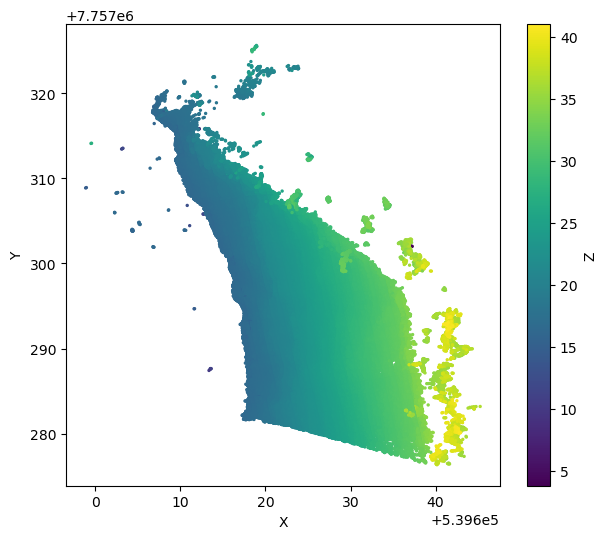

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))

sc = ax.scatter(
    xyz[:, 0],
    xyz[:, 1],
    c=xyz[:, 2],
    s=2,
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_aspect("equal")

plt.colorbar(sc, ax=ax, label="Z")
plt.show()

### Query individual point time series

In [10]:
# distance_variable (smoothed_distance) is returned by default
points = data.query_points(
    [100, 200, 300]
)

points

<xarray.Dataset> Size: 29kB
Dimensions:            (point: 3, time: 909)
Coordinates:
  * point              (point) int64 24B 100 200 300
  * time               (time) datetime64[ns] 7kB 2021-04-18T14:45:00 ... 2021...
Data variables:
    smoothed_distance  (point, time) float64 22kB ...
Attributes:
    coordinates_complete:           true
    schema_name:                    4D-OBC HDF5 analysis
    schema_version:                 0.1.0
    dataset_id:                     FinRiverbank
    point_index_semantics:          Original py4dgeo core-point index
    time_index_semantics:           Original py4dgeo time index
    obc_end_epoch_semantics:        Inclusive
    smoothed_distance_available:    true
    distance_for_compute_variable:  smoothed_distance
    uncertainties_complete:         true
    conversion_complete:            true

In [11]:
# Request specific variables when needed:
variables = [
    "m3c2_distance",
    "smoothed_distance",
    "uncertainty_lodetection",
]

points = data.query_points(
    [100, 200, 300],
    variables=variables,
)

points

<xarray.Dataset> Size: 73kB
Dimensions:                  (point: 3, time: 909)
Coordinates:
  * point                    (point) int64 24B 100 200 300
  * time                     (time) datetime64[ns] 7kB 2021-04-18T14:45:00 .....
Data variables:
    m3c2_distance            (point, time) float64 22kB ...
    smoothed_distance        (point, time) float64 22kB ...
    uncertainty_lodetection  (point, time) float64 22kB ...
Attributes:
    coordinates_complete:           true
    schema_name:                    4D-OBC HDF5 analysis
    schema_version:                 0.1.0
    dataset_id:                     FinRiverbank
    point_index_semantics:          Original py4dgeo core-point index
    time_index_semantics:           Original py4dgeo time index
    obc_end_epoch_semantics:        Inclusive
    smoothed_distance_available:    true
    distance_for_compute_variable:  smoothed_distance
    uncertainties_complete:         true
    conversion_complete:            true

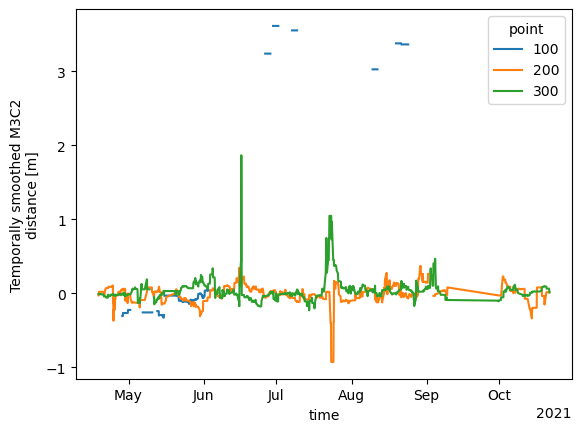

In [12]:
# Plot the preferred distance variable for the selected points:
points[data.distance_variable].plot.line(
    x="time",
    hue="point",
)

More visualization examples refer to: https://docs.xarray.dev/en/stable/gallery.html

### Query by time range

In [13]:
points = data.query_points(
    [100, 200, 300],
    time=slice(100, 120),
)

points["time"]

<xarray.DataArray 'time' (time: 20)> Size: 160B
array(['2021-05-09T14:45:00.000000000', '2021-05-09T16:45:00.000000000',
       '2021-05-09T18:45:00.000000000', '2021-05-10T12:45:00.000000000',
       '2021-05-10T14:45:00.000000000', '2021-05-10T16:45:00.000000000',
       '2021-05-10T18:45:00.000000000', '2021-05-11T10:45:00.000000000',
       '2021-05-11T12:45:00.000000000', '2021-05-11T14:45:00.000000000',
       '2021-05-11T16:45:00.000000000', '2021-05-11T18:45:00.000000000',
       '2021-05-11T20:45:00.000000000', '2021-05-12T08:45:00.000000000',
       '2021-05-12T10:45:00.000000000', '2021-05-12T12:45:00.000000000',
       '2021-05-12T14:45:00.000000000', '2021-05-12T16:45:00.000000000',
       '2021-05-12T18:45:00.000000000', '2021-05-12T20:45:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 160B 2021-05-09T14:45:00 ... 2021-05-12T20...

### Query by spatial

In [14]:
# Define a bbox or define a polygon using Shapely:
xmin = 539600.857
xmax = xmin + 10
ymin = 7757300.335
ymax = ymin + 10


# Find all core points inside an XY bounding box:
point_indices = data.point_indices_bbox(
    xmin=xmin,
    ymin=ymin,
    xmax=xmax,
    ymax=ymax,
)

point_indices

array([ 74282,  74401,  78965,  78969,  78970,  78973,  78975,  78979,
        78980,  78981,  78984,  78986,  78993,  78994,  78998,  78999,
        79001,  79003,  79006,  79007,  79012,  79013,  79343,  79344,
        79345,  79351,  79352,  79353,  79354,  79355,  79358,  79360,
        79361,  79362,  79363,  79366,  79367,  79368,  79377,  79378,
        79385,  79386,  79387,  79388,  79389,  79390,  79392,  79395,
        79398,  79399,  79401,  79402,  79403,  79404,  79405,  79406,
        79407,  79408,  79409,  79412,  79415,  79416,  79417,  79418,
        79425,  79426,  79427,  79428,  79430,  79431,  79432,  79434,
        79437,  79438,  79439,  79441,  79442,  79443,  79444,  79446,
        79447,  79448,  79449,  79454,  79456,  79458,  79461,  79463,
        79465,  79466,  79468,  79473,  79476,  79478,  79479,  79481,
        79482,  79483,  79484,  79488,  79489,  79493,  79495,  79498,
        79500,  79501,  79505,  79507,  79508,  79511,  79512,  79513,
      

In [15]:
# Retrieve their time series directly:

subset = data.query_bbox(
    xmin=xmin,
    ymin=ymin,
    xmax=xmax,
    ymax=ymax,
)

subset

<xarray.Dataset> Size: 1MB
Dimensions:            (point: 179, time: 909)
Coordinates:
  * point              (point) int64 1kB 74282 74401 78965 ... 120220 120221
  * time               (time) datetime64[ns] 7kB 2021-04-18T14:45:00 ... 2021...
Data variables:
    smoothed_distance  (point, time) float64 1MB ...
Attributes:
    coordinates_complete:           true
    schema_name:                    4D-OBC HDF5 analysis
    schema_version:                 0.1.0
    dataset_id:                     FinRiverbank
    point_index_semantics:          Original py4dgeo core-point index
    time_index_semantics:           Original py4dgeo time index
    obc_end_epoch_semantics:        Inclusive
    smoothed_distance_available:    true
    distance_for_compute_variable:  smoothed_distance
    uncertainties_complete:         true
    conversion_complete:            true

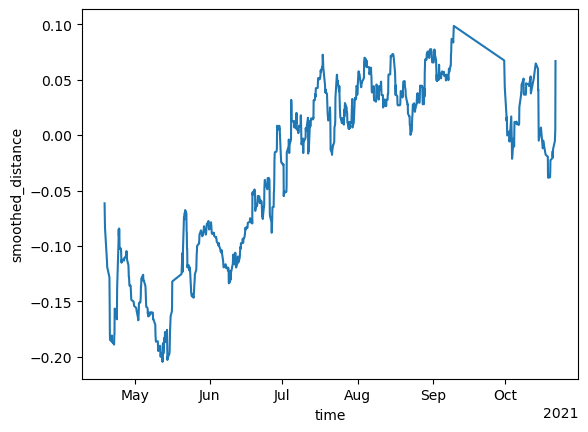

In [16]:
subset[data.distance_variable].mean("point").plot()

### Query one 4D-OBC

In [17]:
# Choose an object from the object table:
row = objects.iloc[0]

object_id = row["object_id"]
display_id = row["display_id"]

print(display_id)
print(object_id)

FinRiverbank-obc-000000
01M3M6J6DDERDPRQCZJ505D5KZ


In [18]:
# Query all corepoints indices belonging to the OBC:
data.obc_point_indices(object_id)

array([17997,   238, 17878,   237,   296, 18047,   270, 17873,   291,
         300,   301,   243,   302,   259,   230,   289, 17866,   284,
         234,   293,   240, 18141,   264,   274, 17915,   266, 18130,
         253,   283, 17886,   245,   246,   220,   278,   280,   251,
         267,   277,   257, 18112,   294,   250, 18068,   260,   231,
         290,   298,   239,   281,   252,   276,   247,   256,   227])

In [19]:
# Retrieve the distance time series for one OBC:

obc = data.query_obc(object_id)
obc

<xarray.Dataset> Size: 2kB
Dimensions:            (point: 54, time: 4)
Coordinates:
  * point              (point) int64 432B 17997 238 17878 237 ... 247 256 227
  * time               (time) datetime64[ns] 32B 2021-07-21T14:45:00 ... 2021...
Data variables:
    smoothed_distance  (point, time) float64 2kB ...
Attributes: (12/16)
    coordinates_complete:           true
    schema_name:                    4D-OBC HDF5 analysis
    schema_version:                 0.1.0
    dataset_id:                     FinRiverbank
    point_index_semantics:          Original py4dgeo core-point index
    time_index_semantics:           Original py4dgeo time index
    ...                             ...
    conversion_complete:            true
    object_id:                      01M3M6J6DDERDPRQCZJ505D5KZ
    display_id:                     FinRiverbank-obc-000000
    obc_index:                      0
    obc_start_epoch:                517
    obc_end_epoch:                  520

In [20]:
# Additional time steps before and after the OBC can be requested using:

obc = data.query_obc(
    object_id,
    temporal_padding=5,
)
obc

<xarray.Dataset> Size: 7kB
Dimensions:            (point: 54, time: 14)
Coordinates:
  * point              (point) int64 432B 17997 238 17878 237 ... 247 256 227
  * time               (time) datetime64[ns] 112B 2021-07-20T18:45:00 ... 202...
Data variables:
    smoothed_distance  (point, time) float64 6kB ...
Attributes: (12/16)
    coordinates_complete:           true
    schema_name:                    4D-OBC HDF5 analysis
    schema_version:                 0.1.0
    dataset_id:                     FinRiverbank
    point_index_semantics:          Original py4dgeo core-point index
    time_index_semantics:           Original py4dgeo time index
    ...                             ...
    conversion_complete:            true
    object_id:                      01M3M6J6DDERDPRQCZJ505D5KZ
    display_id:                     FinRiverbank-obc-000000
    obc_index:                      0
    obc_start_epoch:                517
    obc_end_epoch:                  520

In [21]:
# To retrieve coordinates together with the time series, request them explicitly:

variable = data.distance_variable # "smoothed_distance" or "m3c2_distance"

obc = data.query_obc(
    object_id,
    variables=[
        "x",
        "y",
        "z",
        variable,
    ],
    load=True,
)

obc

<xarray.Dataset> Size: 3kB
Dimensions:            (point: 54, time: 4)
Coordinates:
  * point              (point) int64 432B 17997 238 17878 237 ... 247 256 227
  * time               (time) datetime64[ns] 32B 2021-07-21T14:45:00 ... 2021...
Data variables:
    x                  (point) float64 432B 5.396e+05 5.396e+05 ... 5.396e+05
    y                  (point) float64 432B 7.757e+06 7.757e+06 ... 7.757e+06
    z                  (point) float64 432B 30.22 30.32 30.15 ... 30.15 30.13
    smoothed_distance  (point, time) float64 2kB 0.4796 0.4796 ... 0.2829 0.2829
Attributes: (12/16)
    coordinates_complete:           true
    schema_name:                    4D-OBC HDF5 analysis
    schema_version:                 0.1.0
    dataset_id:                     FinRiverbank
    point_index_semantics:          Original py4dgeo core-point index
    time_index_semantics:           Original py4dgeo time index
    ...                             ...
    conversion_complete:            true
    object_id:                      01M3M6J6DDERDPRQCZJ505D5KZ
    display_id:                     FinRiverbank-obc-000000
    obc_index:                      0
    obc_start_epoch:                517
    obc_end_epoch:                  520

In [22]:
# check metadata
obc.attrs

{'coordinates_complete': 'true',
 'schema_name': '4D-OBC HDF5 analysis',
 'schema_version': '0.1.0',
 'dataset_id': 'FinRiverbank',
 'point_index_semantics': 'Original py4dgeo core-point index',
 'time_index_semantics': 'Original py4dgeo time index',
 'obc_end_epoch_semantics': 'Inclusive',
 'smoothed_distance_available': 'true',
 'distance_for_compute_variable': 'smoothed_distance',
 'uncertainties_complete': 'true',
 'conversion_complete': 'true',
 'object_id': '01M3M6J6DDERDPRQCZJ505D5KZ',
 'display_id': 'FinRiverbank-obc-000000',
 'obc_index': 0,
 'obc_start_epoch': 517,
 'obc_end_epoch': 520}

### Plotting OBC

C:\Users\jiapan\AppData\Local\Temp\ipykernel_39348\3474331589.py:45: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_time.legend()


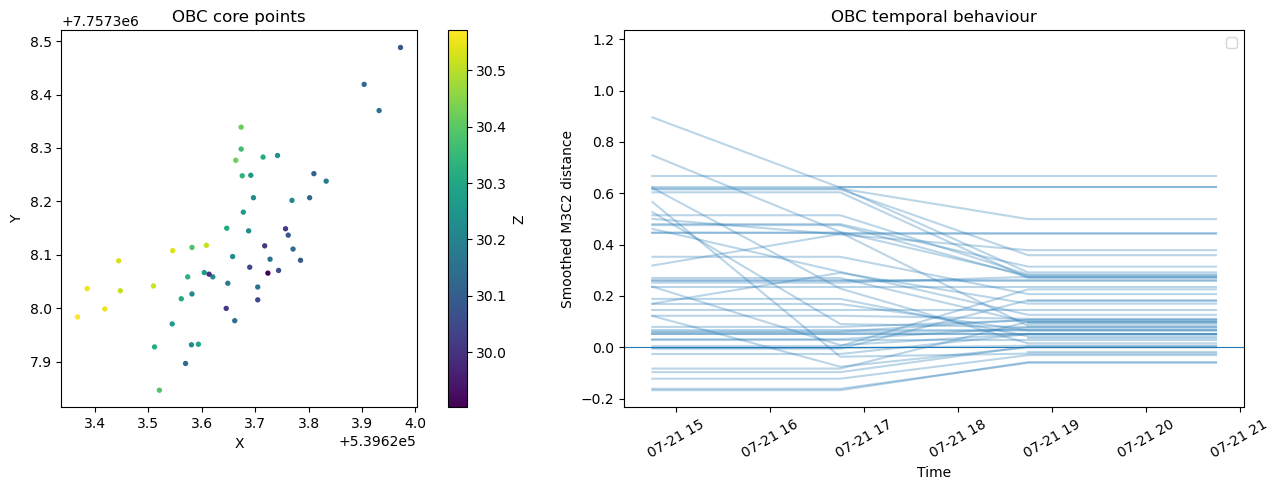

In [23]:
import matplotlib.pyplot as plt

fig, (ax_space, ax_time) = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

# Spatial distribution
sc = ax_space.scatter(
    obc["x"],
    obc["y"],
    c=obc["z"],
    s=8,
)

ax_space.set_xlabel("X")
ax_space.set_ylabel("Y")
ax_space.set_aspect("equal")
ax_space.set_title("OBC core points")

fig.colorbar(
    sc,
    ax=ax_space,
    label="Z",
)


# Temporal behaviour
ts = obc["smoothed_distance"]

for p_ts in ts:
    ax_time.plot(
        obc["time"],
        p_ts,
        alpha=0.3,
        color="C0",
    )

ax_time.axhline(0, linewidth=0.8)
ax_time.set_xlabel("Time")
ax_time.tick_params(axis="x", labelrotation=30)
ax_time.set_ylabel("Smoothed M3C2 distance")
ax_time.set_title("OBC temporal behaviour")
ax_time.legend()

plt.tight_layout()
plt.show()

## 5.Close the dataset

In [24]:
# When finished:
data.close()

# or using a context manager:
with OBCH5(obch5_path) as data:
    print(data.dataset_id)
    print(data.analysis.sizes)

FinRiverbank
Frozen({'point': 195605, 'time': 909})
